# RQ2 — Comparison of Retrieval Policies

This notebook computes the policy-level comparison table requested in `RQs/RQ2/readme.md`: one row per policy with mean final NDCG@50, mean final Recall@50, mean cumulative abstract cost, and mean cumulative latency.

The terminal row of each trace (`terminal == 1`) already stores the final cumulative cost and latency for that query, so the aggregation is simply:
1. Keep the last terminal row per `query_id`.
2. Average the terminal values across the 50 evaluation queries.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

CSV_DIR = Path("../relevant_csvs")

policy_files = {
    "Always STOP": "stop_traces_50_msmarco_dev.csv",
    "Rerank → STOP": "rerank_traces_50_msmarco_dev.csv",
    "PRF → STOP": None,  # placeholder: no CSV available yet
    "Reformulate → STOP": "reformulate_traces_50_msmarco_dev.csv",
    "Random": "random_traces_50_msmarco_dev.csv",
    "Greedy oracle / two-step expert": "expert_traces_50_msmarco_dev.csv",
    "Learned CQL policy": "cql_full_tree_traces_50_msmarco_dev.csv",
}


def summarize_policy(name, file_name):
    """Return mean final NDCG, Recall, cumulative cost and latency for a policy."""
    if file_name is None:
        return pd.Series({
            "Mean final NDCG@50": np.nan,
            "Mean final Recall@50": np.nan,
            "Mean cumulative abstract cost": np.nan,
            "Mean cumulative latency (ms)": np.nan,
        })
    df = pd.read_csv(CSV_DIR / file_name)
    terminal = df[df["terminal"] == 1]
    # Keep the last terminal step per query in case of duplicates.
    terminal = terminal.sort_values("step").groupby("query_id").last()
    return pd.Series({
        "Mean final NDCG@50": terminal["ndcg_after"].mean(),
        "Mean final Recall@50": terminal["recall_after"].mean(),
        "Mean cumulative abstract cost": terminal["cumulative_cost"].mean(),
        "Mean cumulative latency (ms)": terminal["cumulative_latency_ms"].mean(),
    })


policy_table = pd.DataFrame({
    name: summarize_policy(name, fn)
    for name, fn in policy_files.items()
}).T

policy_table

,Mean final NDCG@50,Mean final Recall@50,Mean cumulative abstract cost,Mean cumulative latency (ms)
Always STOP,0.106906,0.160000,0.000000,0.052438
Rerank → STOP,0.110996,0.160000,0.300000,116.895017
PRF → STOP,NaN,NaN,NaN,NaN
Reformulate → STOP,0.035649,0.060000,1.000000,1896.245788
Random,0.094101,0.147059,0.497059,2064.973047
Greedy oracle / two-step expert,0.146751,0.180000,0.096000,192.592287
Learned CQL policy,0.078178,0.140000,0.404000,822.665586


In [3]:
# Print the LaTeX source for the comparison table.
print(policy_table.to_latex(
    float_format="%.3f",
    na_rep="---",
    caption="Comparison of Retrieval Policies: Effectiveness, Cost, and Latency",
    label="tab:rq2_policy_comparison",
))

\begin{table}
\caption{Comparison of Retrieval Policies: Effectiveness, Cost, and Latency}
\label{tab:rq2_policy_comparison}
\begin{tabular}{lrrrr}
\toprule
 & Mean final NDCG@50 & Mean final Recall@50 & Mean cumulative abstract cost & Mean cumulative latency (ms) \\
\midrule
Always STOP & 0.107 & 0.160 & 0.000 & 0.052 \\
Rerank → STOP & 0.111 & 0.160 & 0.300 & 116.895 \\
PRF → STOP & --- & --- & --- & --- \\
Reformulate → STOP & 0.036 & 0.060 & 1.000 & 1896.246 \\
Random & 0.094 & 0.147 & 0.497 & 2064.973 \\
Greedy oracle / two-step expert & 0.147 & 0.180 & 0.096 & 192.592 \\
Learned CQL policy & 0.078 & 0.140 & 0.404 & 822.666 \\
\bottomrule
\end{tabular}
\end{table}



## Notes

- Values are computed directly from the terminal rows of each trace CSV.
- The `PRF → STOP` row is reserved (`---`) because no corresponding CSV exists in `RQs/relevant_csvs/` yet.
- The table is also saved to `RQs/RQ2/latex_tables.tex` for inclusion in the paper.

## Two-panel scatter: NDCG vs. cost and latency

Two-panel scatter plot with mean cumulative cost or mean cumulative latency on the x-axis and mean final NDCG@50 on the y-axis. Policies shown: Always STOP, Rerank → STOP, Reformulate → STOP, Random, Greedy oracle, and Learned CQL policy.

In [15]:
import matplotlib.pyplot as plt

scatter_policies = {
    "Always STOP": "stop_traces_50_msmarco_dev.csv",
    "CQL (low stop)": "cql_full_tree_50_msmarco_traces_low_stop.csv",
    "CQL (stop penalty)": "cql_full_tree_stop_penalty_traces_50_msmarco_dev.csv",
    # "CQL (alpha1.5)": "cql_full_tree_50_msmarco_traces_alpha15.csv",
    # " CQL (alpha1.0)": "cql_full_tree_50_msmarco_traces_alpha10.csv",
    # "CQL (alpha0.5)": "cql_full_tree_50_msmarco_traces_alpha05.csv",
    "Rerank → STOP": "rerank_traces_50_msmarco_dev.csv",
    "Reformulate → STOP": "reformulate_traces_50_msmarco_dev.csv",
    "Random": "random_traces_50_msmarco_dev.csv",
    "Greedy oracle": "expert_traces_50_msmarco_dev.csv",
    "Learned CQL policy": "cql_full_tree_traces_50_msmarco_dev.csv",
}


def policy_means(file_name):
    """Return Series of mean terminal NDCG, cost and latency for a policy."""
    df = pd.read_csv(CSV_DIR / file_name)
    terminal = df[df["terminal"] == 1]
    terminal = terminal.sort_values("step").groupby("query_id").last()
    return terminal[["ndcg_after", "cumulative_cost", "cumulative_latency_ms"]].mean()


scatter_rows = []
for label, fn in scatter_policies.items():
    means = policy_means(fn)
    scatter_rows.append({
        "policy": label,
        "ndcg": means["ndcg_after"],
        "cost": means["cumulative_cost"],
        "latency": means["cumulative_latency_ms"],
    })

scatter_df = pd.DataFrame(scatter_rows)
scatter_df

,policy,ndcg,cost,latency
0,Always STOP,0.106906,0.000000,0.052438
1,CQL (low stop),0.071538,0.453191,2010.495316
2,CQL (stop penalty),0.108179,0.236957,436.331566
3,Rerank → STOP,0.110996,0.300000,116.895017
4,Reformulate → STOP,0.035649,1.000000,1896.245788
5,Random,0.094101,0.497059,2064.973047
6,Greedy oracle,0.146751,0.096000,192.592287
7,Learned CQL policy,0.078178,0.404000,822.665586


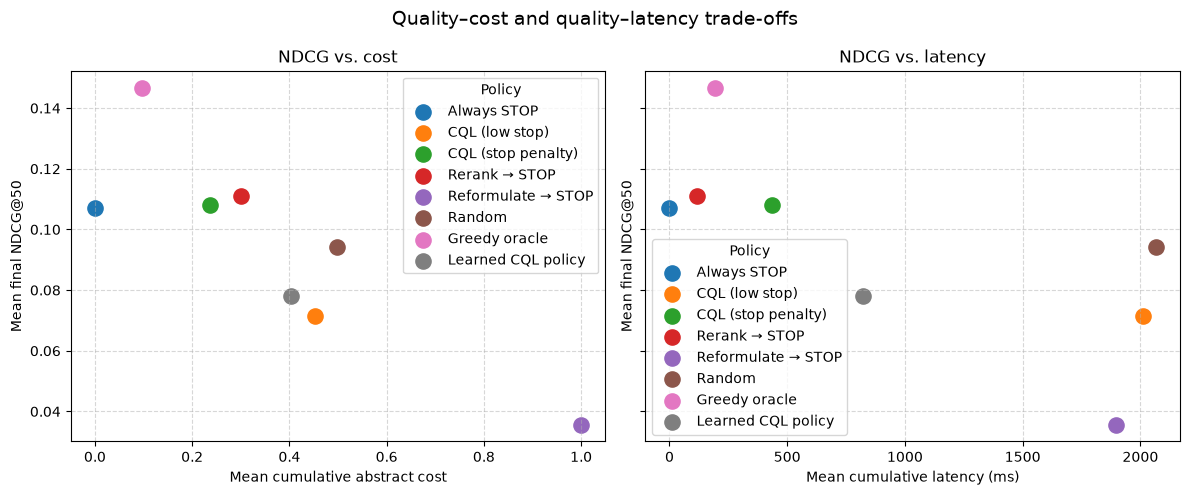

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Panel 1: NDCG vs. cumulative cost
ax = axes[0]
for _, row in scatter_df.iterrows():
    ax.scatter(row["cost"], row["ndcg"], s=120, label=row["policy"])
ax.set_xlabel("Mean cumulative abstract cost")
ax.set_ylabel("Mean final NDCG@50")
ax.set_title("NDCG vs. cost")
ax.legend(title="Policy", loc="best")
ax.grid(True, linestyle="--", alpha=0.5)

# Panel 2: NDCG vs. cumulative latency
ax = axes[1]
for _, row in scatter_df.iterrows():
    ax.scatter(row["latency"], row["ndcg"], s=120, label=row["policy"])
ax.set_xlabel("Mean cumulative latency (ms)")
ax.set_ylabel("Mean final NDCG@50")
ax.set_title("NDCG vs. latency")
ax.legend(title="Policy", loc="best")
ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Quality–cost and quality–latency trade-offs", fontsize=14)
fig.tight_layout()
plt.show()

## Query-level gains and losses

The readme asks for one figure with three vertically stacked panels showing, for each evaluation query, the change in NDCG relative to the initial BM25 retrieval:

\[\Delta \text{NDCG}_q = \text{NDCG}_{q,\text{policy}} - \text{NDCG}_{q,\text{initial BM25}}\]

Panels: Learned CQL policy, Always rerank, Greedy oracle, and Random. All panels share the same query ordering (sorted by initial BM25 NDCG from low to high) and the same y-axis limits. Random can be removed by commenting out its entry in the policy dictionary above.

In [29]:
# Initial BM25 NDCG comes from the STOP baseline (step 1, before any action).
stop_df = pd.read_csv(CSV_DIR / "stop_traces_50_msmarco_dev.csv")
initial_ndcg = (
    stop_df[stop_df["step"] == 1]
    .set_index("query_id")["ndcg_before"]
    .rename("initial_ndcg")
)


def final_ndcg_per_query(file_name):
    """Return final NDCG@50 per query for a policy."""
    df = pd.read_csv(CSV_DIR / file_name)
    terminal = df[df["terminal"] == 1]
    terminal = terminal.sort_values("step").groupby("query_id").last()
    return terminal["ndcg_after"]


delta_policies = {
    "Learned CQL policy": "cql_full_tree_traces_50_msmarco_dev.csv",
    "Always rerank": "rerank_traces_50_msmarco_dev.csv",
    "Greedy oracle": "expert_traces_50_msmarco_dev.csv",
    # comment this code section out if you want to omit the random policy out
    "Random": "random_traces_50_msmarco_dev.csv",
}

delta_df = pd.DataFrame({name: final_ndcg_per_query(fn) for name, fn in delta_policies.items()})
delta_df = delta_df.join(initial_ndcg, how="outer")
for name in delta_policies.keys():
    delta_df[f"ΔNDCG ({name})"] = delta_df[name] - delta_df["initial_ndcg"]

# Order queries by initial BM25 NDCG, low to high.
delta_df = delta_df.sort_values("initial_ndcg")
query_order = delta_df.index.astype(str).tolist()

delta_df[["initial_ndcg"] + [f"ΔNDCG ({name})" for name in delta_policies.keys()]]


,initial_ndcg,ΔNDCG (Learned CQL policy),ΔNDCG (Always rerank),ΔNDCG (Greedy oracle),ΔNDCG (Random)
query_id,,,,,
34015,0.000000,0.000000,0.000000,0.000000,0.000000
42568,0.000000,0.000000,0.000000,0.000000,NaN
169778,0.000000,0.000000,0.000000,0.000000,0.000000
266760,0.000000,0.000000,0.000000,0.000000,0.000000
359040,0.000000,0.000000,0.000000,0.000000,NaN
277799,0.000000,0.000000,0.000000,0.000000,0.000000
384406,0.000000,0.000000,0.000000,0.000000,0.000000
472024,0.000000,0.000000,0.000000,0.000000,0.000000
541135,0.000000,0.000000,0.000000,0.000000,NaN


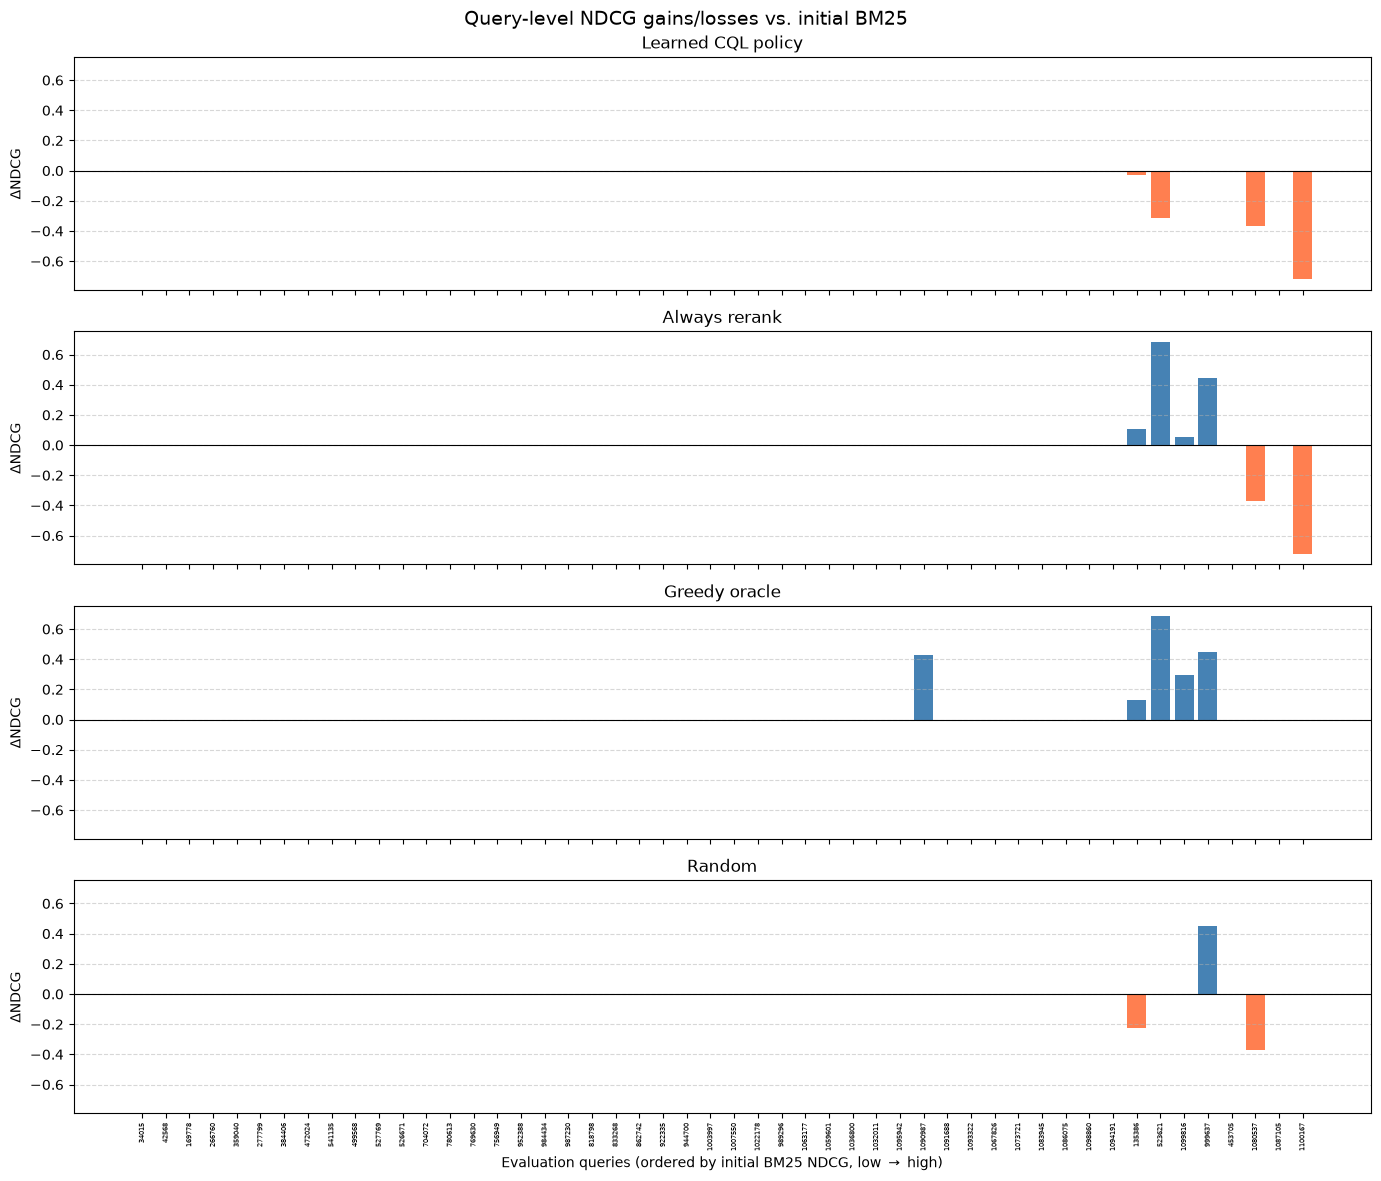

In [30]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True, sharey=True)

for ax, name in zip(axes, delta_policies.keys()):
    values = delta_df[f"ΔNDCG ({name})"]
    colors = ["steelblue" if v >= 0 else "coral" for v in values]
    ax.bar(range(len(values)), values, color=colors, width=0.8)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel(r"$\Delta$NDCG")
    ax.set_title(name)
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)

axes[-1].set_xlabel(r"Evaluation queries (ordered by initial BM25 NDCG, low $\rightarrow$ high)")
axes[-1].set_xticks(range(len(query_order)))
axes[-1].set_xticklabels(query_order, rotation=90, fontsize=5)
fig.suptitle("Query-level NDCG gains/losses vs. initial BM25", 
fontsize=14)
fig.tight_layout()
plt.show()

## Compact query-level impact table

Summary table requested in `RQs/RQ2/readme.md`: for every policy, the percentage of queries improved, unchanged, and worsened relative to initial BM25, plus the mean $\Delta$NDCG.

In [ ]:
impact_policies = {
    "Always STOP": "stop_traces_50_msmarco_dev.csv",
    "Rerank → STOP": "rerank_traces_50_msmarco_dev.csv",
    "PRF → STOP": None,  # placeholder
    "Reformulate → STOP": "reformulate_traces_50_msmarco_dev.csv",
    "Random": "random_traces_50_msmarco_dev.csv",
    "Greedy oracle / two-step expert": "expert_traces_50_msmarco_dev.csv",
    "Learned CQL policy": "cql_full_tree_traces_50_msmarco_dev.csv",
}


def policy_delta_series(file_name):
    """Return per-query ΔNDCG for a policy vs. initial BM25."""
    if file_name is None:
        return pd.Series(dtype=float)
    final = final_ndcg_per_query(file_name)
    return pd.Series(final) - initial_ndcg


impact_rows = []
for name, fn in impact_policies.items():
    deltas = policy_delta_series(fn)
    if len(deltas) == 0:
        impact_rows.append({
            "Policy": name,
            "Queries improved (%)": np.nan,
            "Unchanged (%)": np.nan,
            "Worsened (%)": np.nan,
            "Mean ΔNDCG": np.nan,
        })
    else:
        impact_rows.append({
            "Policy": name,
            "Queries improved (%)": (deltas > 0).mean() * 100,
            "Unchanged (%)": (deltas == 0).mean() * 100,
            "Worsened (%)": (deltas < 0).mean() * 100,
            "Mean ΔNDCG": deltas.mean(),
        })

impact_df = pd.DataFrame(impact_rows)
impact_df


In [ ]:
print(impact_df.to_latex(
    index=False,
    float_format="%.2f",
    na_rep="---",
    caption="Query-Level Impact of Retrieval Policies",
    label="tab:rq2_query_level_impact",
))

## Action distribution plot

A "pizza slice" (pie-chart) figure showing the distribution of action occurrences for three policies: Learned CQL policy, Always rerank, and Greedy oracle. Each action in every trace is classified into one of five categories:

- **Immediate STOP**: `action_name == STOP` and `step == 1`.
- **Later explicit STOP**: `action_name == STOP` and `step > 1`.
- **Reformulate**: `action_name == QueryReform`.
- **Rerank**: `action_name == Rerank`.
- **PRF**: `action_name == PseudoRelevanceFeedback`.

Counts are normalized to percentages within each policy.

In [27]:
action_policies = {
    "Learned CQL policy": "cql_full_tree_traces_50_msmarco_dev.csv",
    "Random": "random_traces_50_msmarco_dev.csv",
    "Greedy oracle": "expert_traces_50_msmarco_dev.csv",
}


def classify_action(row):
    """Classify one trace row into an action category."""
    action = row["action_name"]
    step = row["step"]
    if action == "STOP" and step == 1:
        return "Immediate STOP"
    if action == "STOP" and step > 1:
        return "Later explicit STOP"
    if action == "QueryReform":
        return "Reformulate"
    if action == "Rerank":
        return "Rerank"
    if action == "PseudoRelevanceFeedback":
        return "PRF"
    return "Other"


action_counts = {}
for policy, fn in action_policies.items():
    df = pd.read_csv(CSV_DIR / fn)
    df["action_category"] = df.apply(classify_action, axis=1)
    counts = df["action_category"].value_counts()
    action_counts[policy] = counts

action_df = pd.DataFrame(action_counts).fillna(0).astype(int).T
# Reorder columns to the requested order.
category_order = ["Immediate STOP", "Later explicit STOP", "Reformulate", "Rerank", "PRF"]
action_df = action_df[[c for c in category_order if c in action_df.columns]]
action_pct = action_df.div(action_df.sum(axis=1), axis=0) * 100
action_pct


action_category,Immediate STOP,Later explicit STOP,Reformulate,Rerank,PRF
Learned CQL policy,11.702128,41.489362,10.638298,26.595745,9.574468
Random,8.695652,20.869565,25.217391,21.739130,23.478261
Greedy oracle,76.271186,8.474576,5.084746,5.084746,5.084746


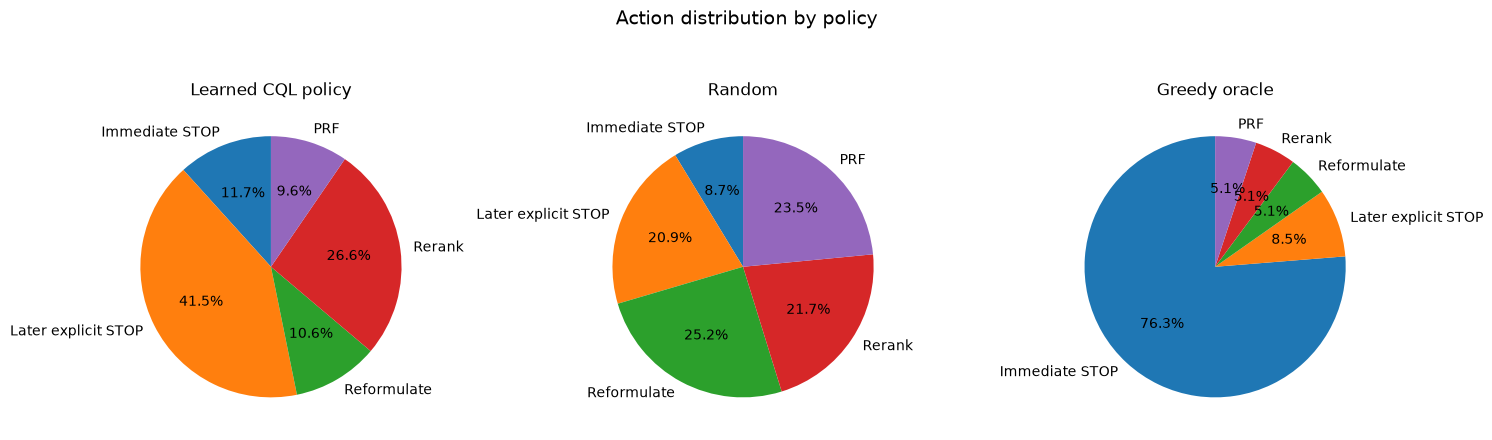

In [28]:
n_policies = len(action_pct)
ncols = 3
nrows = (n_policies + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
axes = np.array(axes).ravel()

colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

for ax, (policy, pct) in zip(axes, action_pct.iterrows()):
    wedges, texts, autotexts = ax.pie(
        pct,
        labels=pct.index,
        autopct="%1.1f%%",
        startangle=90,
        colors=colors,
    )
    ax.set_title(policy)

# Hide any unused subplot slots (e.g. the 4th slot when only 3 policies are shown).
for ax in axes[n_policies:]:
    ax.axis("off")

fig.suptitle("Action distribution by policy", fontsize=14)
fig.tight_layout()
plt.show()